In [1]:
from pathlib import Path
from collections import Counter
import os

PROJECT_ROOT = Path.cwd().parent
DATA_ROOT = PROJECT_ROOT / "data" / "Office-31"

DOMAINS = ["amazon", "webcam", "dslr"]

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp"}

print("Project root:", PROJECT_ROOT)
print("Dataset root:", DATA_ROOT)
print("Dataset exists:", DATA_ROOT.exists())

Project root: d:\DUK- Research Collab\Sanjay PhD\cnn-domain-adaptation-optimal-transport
Dataset root: d:\DUK- Research Collab\Sanjay PhD\cnn-domain-adaptation-optimal-transport\data\Office-31
Dataset exists: True


In [2]:
for domain in DOMAINS:
    domain_path = DATA_ROOT / domain

    print(f"\n{'='*50}")
    print(f"DOMAIN: {domain.upper()}")
    print(f"{'='*50}")

    if not domain_path.exists():
        print("Domain directory missing!")
        continue

    for item in sorted(domain_path.iterdir()):
        kind = "Directory" if item.is_dir() else "File"
        print(f"{kind}: {item.name}")


DOMAIN: AMAZON
Directory: back_pack
Directory: bike
Directory: bike_helmet
Directory: bookcase
Directory: bottle
Directory: calculator
Directory: desk_chair
Directory: desk_lamp
Directory: desktop_computer
Directory: file_cabinet
Directory: headphones
Directory: keyboard
Directory: laptop_computer
Directory: letter_tray
Directory: mobile_phone
Directory: monitor
Directory: mouse
Directory: mug
Directory: paper_notebook
Directory: pen
Directory: phone
Directory: printer
Directory: projector
Directory: punchers
Directory: ring_binder
Directory: ruler
Directory: scissors
Directory: speaker
Directory: stapler
Directory: tape_dispenser
Directory: trash_can

DOMAIN: WEBCAM
Directory: back_pack
Directory: bike
Directory: bike_helmet
Directory: bookcase
Directory: bottle
Directory: calculator
Directory: desk_chair
Directory: desk_lamp
Directory: desktop_computer
Directory: file_cabinet
Directory: headphones
Directory: keyboard
Directory: laptop_computer
Directory: letter_tray
Directory: mobil

In [3]:
for domain in DOMAINS:
    domain_path = DATA_ROOT / domain

    images = [
        p for p in domain_path.rglob("*")
        if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
    ]

    print(f"{domain:10s}: {len(images):5d} images")

amazon    :  2817 images
webcam    :   795 images
dslr      :   498 images


### Class Distribution Analysis

In [4]:
import pandas as pd

class_counts = {}

for domain in DOMAINS:
    domain_path = DATA_ROOT / domain

    class_counts[domain] = {}

    for class_dir in sorted(domain_path.iterdir()):
        if class_dir.is_dir():
            images = [
                p for p in class_dir.rglob("*")
                if p.is_file()
                and p.suffix.lower() in IMAGE_EXTENSIONS
            ]

            class_counts[domain][class_dir.name] = len(images)

distribution_df = pd.DataFrame(class_counts).fillna(0).astype(int)

distribution_df["Total"] = distribution_df.sum(axis=1)

print("Number of classes:", len(distribution_df))
print("\nClass distribution:")
display(distribution_df)

Number of classes: 31

Class distribution:


,amazon,webcam,dslr,Total
back_pack,92,29,12,133
bike,82,21,21,124
bike_helmet,72,28,24,124
bookcase,82,12,12,106
bottle,36,16,16,68
calculator,94,31,12,137
desk_chair,91,40,13,144
desk_lamp,97,18,14,129
desktop_computer,97,21,15,133
file_cabinet,81,19,15,115


In [5]:
amazon_classes = set(class_counts["amazon"])
webcam_classes = set(class_counts["webcam"])
dslr_classes = set(class_counts["dslr"])

print("Amazon classes:", len(amazon_classes))
print("Webcam classes:", len(webcam_classes))
print("DSLR classes:", len(dslr_classes))

print("Same classes across all domains:",
      amazon_classes == webcam_classes == dslr_classes)

print("\nClasses with zero images:")
display(distribution_df[
    (distribution_df["amazon"] == 0) |
    (distribution_df["webcam"] == 0) |
    (distribution_df["dslr"] == 0)
])

Amazon classes: 31
Webcam classes: 31
DSLR classes: 31
Same classes across all domains: True

Classes with zero images:


,amazon,webcam,dslr,Total


### Visualize Domain differences

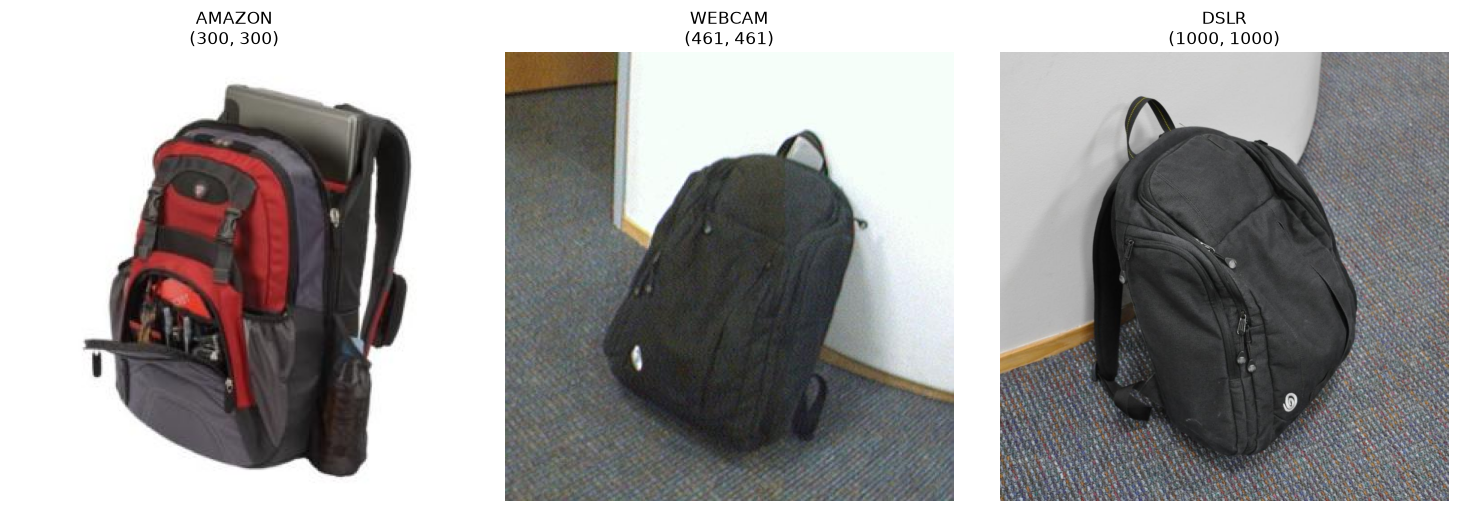

In [6]:
import matplotlib.pyplot as plt
from PIL import Image
import random

random.seed(42)

category = "back_pack"

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, domain in zip(axes, DOMAINS):
    category_path = DATA_ROOT / domain / category

    images = [
        p for p in category_path.iterdir()
        if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
    ]

    image_path = random.choice(images)

    image = Image.open(image_path).convert("RGB")

    ax.imshow(image)
    ax.set_title(f"{domain.upper()}\n{image.size}")
    ax.axis("off")

plt.tight_layout()
plt.show()

### Investigate Image Dimensions

In [7]:
from collections import defaultdict

dimension_data = defaultdict(list)

for domain in DOMAINS:
    image_paths = [
        p for p in (DATA_ROOT / domain).rglob("*")
        if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
    ]

    for image_path in image_paths:
        try:
            with Image.open(image_path) as img:
                dimension_data[domain].append(img.size)
        except Exception as e:
            print("Unreadable image:", image_path, e)

for domain in DOMAINS:
    dimensions = dimension_data[domain]

    widths = [w for w, h in dimensions]
    heights = [h for w, h in dimensions]

    print(f"\n{domain.upper()}")
    print("Images inspected:", len(dimensions))
    print("Width - min/max:", min(widths), max(widths))
    print("Height - min/max:", min(heights), max(heights))
    print("Unique dimensions:", len(set(dimensions)))


AMAZON
Images inspected: 2817
Width - min/max: 300 301
Height - min/max: 300 301
Unique dimensions: 2

WEBCAM
Images inspected: 795
Width - min/max: 152 752
Height - min/max: 152 752
Unique dimensions: 302

DSLR
Images inspected: 498
Width - min/max: 1000 1001
Height - min/max: 1000 1001
Unique dimensions: 2


### Experimental Data Splitting

In [8]:
from sklearn.model_selection import train_test_split
from pathlib import Path
import pandas as pd

SEED = 42

def collect_images(domain):
    domain_path = DATA_ROOT / domain

    records = []

    for class_dir in sorted(domain_path.iterdir()):
        if not class_dir.is_dir():
            continue

        for image_path in class_dir.rglob("*"):
            if image_path.is_file() and image_path.suffix.lower() in IMAGE_EXTENSIONS:
                records.append({
                    "path": str(image_path.resolve()),
                    "label": class_dir.name
                })

    return pd.DataFrame(records)

In [9]:
amazon_df = collect_images("amazon")

source_train, source_test = train_test_split(
    amazon_df,
    test_size=0.20,
    random_state=SEED,
    stratify=amazon_df["label"]
)

source_train = source_train.reset_index(drop=True)
source_test = source_test.reset_index(drop=True)

print("Source training:", len(source_train))
print("Source evaluation:", len(source_test))

Source training: 2253
Source evaluation: 564


In [10]:
webcam_df = collect_images("webcam")

target_paths = webcam_df["path"].tolist()

target_adapt_paths, target_test_paths = train_test_split(
    target_paths,
    test_size=0.50,
    random_state=SEED
)

print("Target adaptation images:", len(target_adapt_paths))
print("Target test images:", len(target_test_paths))

Target adaptation images: 397
Target test images: 398


In [11]:
target_test = pd.DataFrame({
    "path": target_test_paths,
    "label": [
        Path(path).parent.name
        for path in target_test_paths
    ]
})

print("Target test images:", len(target_test))
print("Target test classes:", target_test["label"].nunique())

print("\nSource training classes:", source_train["label"].nunique())
print("Source evaluation classes:", source_test["label"].nunique())

Target test images: 398
Target test classes: 31

Source training classes: 31
Source evaluation classes: 31


In [12]:
# Save dataset splits for reuse in other notebooks

from pathlib import Path
import pandas as pd

split_manifest = pd.concat([
    source_train.assign(split="source_train"),
    source_test.assign(split="source_test"),

    pd.DataFrame({
        "path": target_adapt_paths,
        "label": None,
        "split": "target_adapt"
    }),

    target_test.assign(split="target_test")

], ignore_index=True)

SPLIT_DIR = PROJECT_ROOT / "experiments"
SPLIT_DIR.mkdir(parents=True, exist_ok=True)

split_manifest.to_csv(
    SPLIT_DIR / "office31_splits.csv",
    index=False
)

print(split_manifest["split"].value_counts())
print("Splits saved!")

split
source_train    2253
source_test      564
target_test      398
target_adapt     397
Name: count, dtype: int64
Splits saved!
